# Notebook 7 — FCC-ee: change beta star with open matching

Load the FCC-ee Z lattice and increase both interaction-point beta functions by a factor of **ten**, from approximately **90 mm / 0.8 mm** to **900 mm / 8 mm**.

Use the dispersion-free matching sections between the dispersion suppressors (DS) and the interior of the interaction region (IR). Keep the inner IR, final-focus, and dispersive DS magnets fixed.

## Your tasks

1. Load `fccee_z.json`, select `fccee_p_ring`, and calculate nominal periodic 4D Twiss.
2. Select the insertion around `ipd`, bounded by `end_ds_start_straight_ipd` and `end_straight_start_ds_ipd`. Inspect the nominal beta functions, dispersion, and matching quadrupoles.
3. Calculate **open Twiss from each DS boundary to the IP**, using the nominal DS optics as fixed initial conditions. Propagate forwards on the left and backwards on the right.
4. Make $\beta_x^*=10\beta_{x,0}^*$, $\beta_y^*=10\beta_{y,0}^*$, and $\alpha_x^*=\alpha_y^*=0$ the **matching targets at the IP**. Use `solve_homotopy()` on each half-insertion to approach them gradually.
5. Inspect the targets and strengths, compare the optics before and after, and verify the factor-ten change with periodic full-ring Twiss.
6. Restore the nominal tunes using the arc quadrupole circuits `kqf2` and `kqd1`, and check the final beta-star values.
7. Restore the nominal linear chromaticities using the arc sextupole families `ksf1` and `ksd1`.
8. Compare the natural chromaticities of the two optics, using copies with sextupoles switched off.
9. Save the nominal and matched rings to JSON for subsequent tracking studies.

The DS optics are fixed boundary conditions, while the IP optics are targets. The strength knobs are shared by all four collision insertions, so all four IPs change together. This exercise matches linear transverse optics with radiation off; the arc quadrupole circuits restore the nominal tunes after the local beta-star match. The arc sextupoles then restore the nominal linear chromaticities.

See the [Xsuite examples of open matching](https://xsuite.readthedocs.io/en/latest/match.html#match-at-specific-locations).

### Load the lattice and calculate the nominal optics

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import xtrack as xt

In [2]:
env = xt.load('fccee_z.json')
line = env.fccee_p_ring
line.configure_radiation(model=None)

tw0 = line.twiss4d(delta_chrom=1e-6)
print(f'Energy: {line.particle_ref.energy0[0] / 1e9:.2f} GeV')
print(f'Circumference: {line.get_length() / 1e3:.3f} km')
print(f'Nominal tunes: {tw0.qx:.5f} / {tw0.qy:.5f}')

Loading line from dict:   0%|          | 0/19024 [00:00<?, ?it/s]

Energy: 45.60 GeV
Circumference: 90.660 km
Nominal tunes: 166.16000 / 162.20000


### Save the nominal ring

Export the nominal optics to `fccee_z_nominal.json` before changing any matching knobs.

In [3]:
line.to_json('fccee_z_nominal.json')

### Natural chromaticity of the nominal optics

Natural chromaticity is the tune derivative with respect to relative momentum deviation with the sextupoles switched off. Use a separate copy so that the original lattice and its sextupole settings are preserved. In this lattice, all nonzero sextupole strengths are in `Sextupole` elements.

Use a small momentum step, `delta_chrom=1e-6`: without sextupole correction, the large chromaticity makes the default off-momentum probes unstable.

In [4]:
line_natural = line.copy()
tt_natural = line_natural.get_table()
for name in tt_natural.rows[tt_natural.element_type == 'Sextupole'].name:
    line_natural[name].k2 = 0

tw_natural_0 = line_natural.twiss4d(delta_chrom=1e-6)
print(f'Nominal natural chromaticities: {tw_natural_0.dqx:.3f} / {tw_natural_0.dqy:.3f}')

Nominal natural chromaticities: -512.539 / -3145.903


In [5]:
ip = 'ipd'
start = 'end_ds_start_straight_ipd'
end = 'end_straight_start_ds_ipd'

tw0.rows[[start, ip, end]].cols['s betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 8 cols
name                                  s          betx          bety          alfx          alfy ...
end_ds_start_straight_ipd       21301.4       165.464       476.699      -2.48637      -1.02472
ipd                             22665.1          0.09        0.0008  -5.88247e-09  -2.53742e-08
end_straight_start_ds_ipd       24028.7       165.464       476.699       2.48637       1.02473

### Inspect the insertion and the matching sections

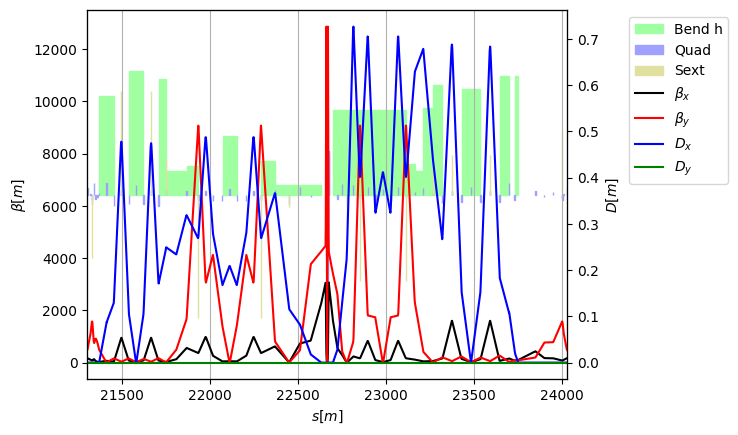

In [6]:
tw0.rows[start:end].plot()

### Select the matching quadrupoles

Vary all quadrupoles in the nominally dispersion-free matching sections between the DS boundaries and the IR bends: **eight on the left** and **seven on the right**.

On the left, use `qd8m`, `qf9m`, `qd10m`, `qd20l`, `qf19l`, `qd18l`, `qf17l`, and `qd16l`. On the right, use `qf17r`, `qd18r`, `qf19r`, `qd20r`, `qd10m`, `qf9m`, and `qd8m`.

The `qd8m`, `qf9m`, and `qd10m` families initially share knobs between the two sides. Give the right-side occurrences separate knobs, leaving the original knobs for the left side. Each knob remains shared across the four collision insertions. Using the complete sections gives more flexibility for larger beta-star changes.

In [7]:
for family in ['qd8m', 'qf9m', 'qd10m']:
    knob = 'k' + family + 'r'
    env[knob] = env['k' + family]
    for index in [0, 2, 4, 6]:  # Right sides of the four collision insertions
        env.ref[f'{family}.{index}'].k1 = env.ref[knob]

knobs_left = ['kqd16l', 'kqf17l', 'kqd18l', 'kqf19l', 'kqd20l',
              'kqd8m', 'kqf9m', 'kqd10m']
knobs_right = ['kqf17r', 'kqd18r', 'kqf19r', 'kqd20r',
               'kqd8mr', 'kqf9mr', 'kqd10mr']
quad_names = [
    'qd8m.1', 'qf9m.1', 'qd10m.1', 'qd20l.0',
    'qf19l.0', 'qd18l.0', 'qf17l.0', 'qd16l.0',
    'qf17r.1', 'qd18r.1', 'qf19r.1', 'qd20r.1',
    'qd10m.2', 'qf9m.2', 'qd8m.2',
]
tw0.rows[quad_names].cols['s betx bety dx dpx']

TwissTable: 15 rows, 6 cols
name                s          betx          bety            dx           dpx
qd8m.1        21301.5       166.211       477.006  -2.01631e-05  -2.55176e-07
qf9m.1        21320.4       108.936       1108.05  -1.52995e-05   2.84486e-07
qd10m.1       21327.3       83.3572       1511.97  -1.28127e-05   3.80925e-07
qd20l.0       21330.1       80.0025          1575  -1.22635e-05   1.07358e-07
qf19l.0       21338.9       133.144        817.78  -1.47829e-05  -3.25344e-07
qd18l.0       21348.5       71.7408        910.16  -9.95913e-06   6.19443e-07
qf17l.0       21358.1       37.5709       804.881  -5.68902e-06   4.19982e-07
qd16l.0       21367.7       24.4597       539.874  -2.13184e-06   3.63282e-07
qf17r.1       23847.5       432.219       194.674  -3.27319e-05  -2.20465e-07
qd18r.1       23898.1       176.884       756.875  -2.19506e-05   2.20035e-07
qf19r.1       23948.7       167.099       783.349  -2.14069e-05   7.38755e-09
qd20r.1       23999.3        80.397 

### Open Twiss with fixed DS boundary conditions

Each half-insertion has its own nominal DS initialization. For the right half, `init_at=end` propagates the optics backwards from the downstream DS boundary to the IP. Neither calculation imposes periodicity.

In [8]:
init_left = tw0.get_twiss_init(start)
init_right = tw0.get_twiss_init(end)

tw_left = line.twiss4d(start=start, end=ip, init=init_left)
tw_right = line.twiss4d(start=ip, end=end, init=init_right, init_at=end)
tw_left.rows[ip].cols['betx bety alfx alfy']

TwissTable: 1 row, 5 cols
name          betx          bety          alfx          alfy
ipd           0.09        0.0008  -5.88315e-09  -3.03911e-08

In [9]:
tw_right.rows[ip].cols['betx bety alfx alfy']

TwissTable: 1 row, 5 cols
name          betx          bety          alfx          alfy
ipd           0.09        0.0008  -5.72277e-09  -2.87083e-08

### Define the IP targets

Both halves must reach the same enlarged waist. The weights balance the horizontal beta in tenths of metres and vertical beta in millimetres against the alpha targets. The initial conditions at the DS boundaries remain fixed.

In [10]:
env['beta_factor'] = 10
env['betx_star'] = tw0['betx', ip]
env['bety_star'] = tw0['bety', ip]
targets_ip = [
    xt.Target('betx', at=ip, value=env.new_expr('beta_factor * betx_star'), tol=1e-8, weight=10),
    xt.Target('bety', at=ip, value=env.new_expr('beta_factor * bety_star'), tol=1e-10, weight=1000),
    xt.TargetSet(alfx=0, alfy=0, at=ip, tol=1e-7),
]


### Match the left half with homotopy

`solve_homotopy(n_steps=45)` moves the target values in 45 equal steps from their initial values to the requested ones, solving at each step. Here the beta-star factor increases from 1 to 10 in steps of 0.2.

Evaluate `target_status()` before starting, to display and initialize the current target values. If an intermediate solve fails, homotopy can return before reaching the final targets; check the final factor explicitly below.

In [11]:
opt_left = line.match(
    solve=False, method='4d',
    start=start, end=ip, init=init_left,
    vary=xt.VaryList(knobs_left, step=1e-8),
    targets=targets_ip,
    n_steps_max=40,
)
opt_right = line.match(
    solve=False, method='4d',
    start=ip, end=end, init=init_right, init_at=end,
    vary=xt.VaryList(knobs_right, step=1e-8),
    targets=targets_ip,
    n_steps_max=40,
)
opt_left.target_status()
opt_right.target_status()

Target status:               
id state tag      tol_met       residue   current_val target_val                                   description                                 
0  ON    ipd_betx   False         -0.81          0.09 (vars['beta_factor'] * vars['betx_star'] ... ('betx', 'ipd'), val=(vars['beta_factor' ...
1  ON    ipd_bety   False       -0.0072        0.0008 (vars['beta_factor'] * vars['bety_star'] ... ('bety', 'ipd'), val=(vars['beta_factor' ...
2  ON    ipd_alfx    True  -5.88315e-09  -5.88315e-09 0                                            ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True  -3.03911e-08  -3.03911e-08 0                                            ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


Target status:               
id state tag      tol_met       residue   current_val target_val                                   description                                 
0  ON    ipd_betx   False         -0.81          0.09 (vars['beta_factor'] * vars['betx_star'] ... ('betx', 'ipd'), val=(vars['beta_factor' ...
1  ON    ipd_bety   False       -0.0072        0.0008 (vars['beta_factor'] * vars['bety_star'] ... ('bety', 'ipd'), val=(vars['beta_factor' ...
2  ON    ipd_alfx    True  -5.72277e-09  -5.72277e-09 0                                            ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True  -2.87083e-08  -2.87083e-08 0                                            ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


In [12]:
opt_left.solve_homotopy(n_steps=45)

Optimize - start penalty: 0.2408                         


Matching: model call n. 39 penalty = 5.4202e-01              

Matching: model call n. 47 penalty = 1.9523e-01              

Matching: model call n. 59 penalty = 1.6353e-01              

Matching: model call n. 65 penalty = 6.2842e-02              

Matching: model call n. 79 penalty = 1.6443e-04              

... (191 outputs left out)


Optimize - end penalty:  3.00938e-08                            


Optimize - start penalty: 0.2408                         


Matching: model call n. 1773 penalty = 7.0497e-05              


Optimize - end penalty:  3.09826e-08                            


In [13]:
opt_left.target_status()
opt_left.vary_status()

Target status:               
id state tag      tol_met       residue   current_val target_val                                   description                                 
0  ON    ipd_betx    True   7.00285e-11           0.9 (0.0 + (1.0 * (vars['beta_factor'] * var ... ('betx', 'ipd'), val=(0.0 + (1.0 * (vars ...
1  ON    ipd_bety    True  -3.01554e-11         0.008 (0.0 + (1.0 * (vars['beta_factor'] * var ... ('bety', 'ipd'), val=(0.0 + (1.0 * (vars ...
2  ON    ipd_alfx    True   6.59172e-10   6.59172e-10 0.0                                          ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True   2.57542e-10   2.57542e-10 0.0                                          ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...
Vary status:                 
id state tag met name   lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kqd16l None             0.013961 None           0.00276666         1e-08             1
1  ON       

### Match the right half with homotopy

In [14]:
opt_right.target_status()

Target status:               
id state tag      tol_met       residue   current_val target_val                                   description                                 
0  ON    ipd_betx   False         -0.81          0.09 (vars['beta_factor'] * vars['betx_star'] ... ('betx', 'ipd'), val=(vars['beta_factor' ...
1  ON    ipd_bety   False       -0.0072        0.0008 (vars['beta_factor'] * vars['bety_star'] ... ('bety', 'ipd'), val=(vars['beta_factor' ...
2  ON    ipd_alfx    True  -5.72277e-09  -5.72277e-09 0                                            ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True  -2.87083e-08  -2.87083e-08 0                                            ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...


In [15]:
opt_right.solve_homotopy(n_steps=45)

Optimize - start penalty: 0.2408                         


Matching: model call n. 12 penalty = 2.4083e-01              

Matching: model call n. 13 penalty = 9.0612e-01              

Matching: model call n. 31 penalty = 1.6845e-01              


Optimize - end penalty:  1.64376e-07                            


Optimize - start penalty: 0.2408                         


... (193 outputs left out)

Matching: model call n. 1629 penalty = 2.4083e-01              

Matching: model call n. 1632 penalty = 4.5916e-02              

Matching: model call n. 1639 penalty = 4.5696e-02              


Optimize - end penalty:  4.1876e-09                            


In [16]:
opt_right.target_status()
opt_right.vary_status()

Target status:               
id state tag      tol_met       residue   current_val target_val                                   description                                 
0  ON    ipd_betx    True    2.3158e-10           0.9 (0.0 + (1.0 * (vars['beta_factor'] * var ... ('betx', 'ipd'), val=(0.0 + (1.0 * (vars ...
1  ON    ipd_bety    True   4.12182e-13         0.008 (0.0 + (1.0 * (vars['beta_factor'] * var ... ('bety', 'ipd'), val=(0.0 + (1.0 * (vars ...
2  ON    ipd_alfx    True  -3.04366e-10  -3.04366e-10 0.0                                          ('alfx', 'ipd'), val=0, tol=1e-07, weigh ...
3  ON    ipd_alfy    True   1.65507e-10   1.65507e-10 0.0                                          ('alfy', 'ipd'), val=0, tol=1e-07, weigh ...
Vary status:                 
id state tag met name    lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kqf17r  None           0.00452439 None           0.00839602         1e-08             1
1  ON     

### Check that both halves reach the requested IP optics

In [17]:
tw_left = line.twiss4d(start=start, end=ip, init=init_left)
tw_right = line.twiss4d(start=ip, end=end, init=init_right, init_at=end)

print(f'Left beta-star ratios: {tw_left["betx", ip] / tw0["betx", ip]:.6f} / '
      f'{tw_left["bety", ip] / tw0["bety", ip]:.6f}')
print(f'Right beta-star ratios: {tw_right["betx", ip] / tw0["betx", ip]:.6f} / '
      f'{tw_right["bety", ip] / tw0["bety", ip]:.6f}')

Left beta-star ratios: 10.000000 / 10.000000
Right beta-star ratios: 10.000000 / 10.000000


### Propagate through the complete insertion

Start from the left DS boundary and propagate through both matched halves. Inspect the IP waist and the recovery of the nominal right-DS beta and alpha functions. The small dispersion residuals in the supplied lattice are not matching targets.

In [18]:
tw_match = line.twiss4d(start=start, end=end, init=init_left)
tw_match.rows[[start, ip, end]].cols['betx bety alfx alfy dx dpx']

TwissTable: 3 rows, 7 cols
name                               betx          bety          alfx          alfy            dx ...
end_ds_start_straight_ipd       165.464       476.699      -2.48637      -1.02472  -2.01248e-05
ipd                                 0.9         0.008   6.59172e-10   2.57542e-10  -1.29639e-06
end_straight_start_ds_ipd       165.464       476.699       2.48637       1.02473  -1.63021e-05

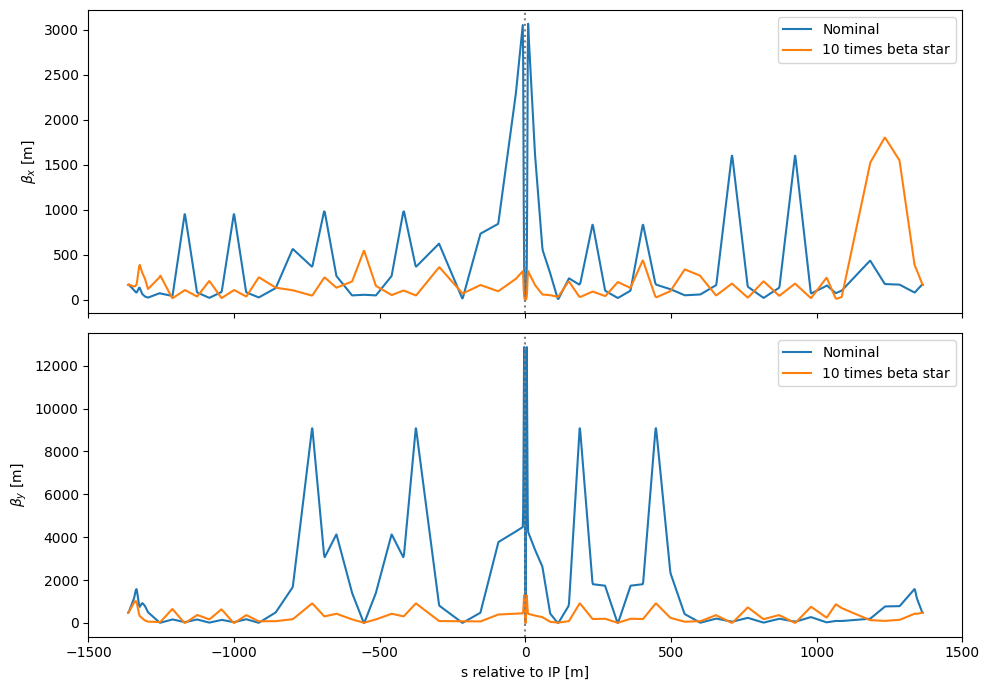

In [19]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7))
for tw, label in [(tw0.rows[start:end], 'Nominal'), (tw_match, '10 times beta star')]:
    s = tw.s - tw0['s', ip]
    axes[0].plot(s, tw.betx, label=label)
    axes[1].plot(s, tw.bety, label=label)
axes[0].set_ylabel(r'$\beta_x$ [m]')
axes[1].set_ylabel(r'$\beta_y$ [m]')
axes[1].set_xlabel('s relative to IP [m]')
for ax in axes:
    ax.axvline(0, color='grey', linestyle=':')
    ax.legend()
plt.tight_layout()

### Restore the tunes with the arc quadrupole circuits

The local beta-star match changes the ring tunes. Use the focusing and defocusing arc circuits, `kqf2` and `kqd1`, to bring them back to their nominal values. These small strength changes also slightly perturb the periodic beta functions; check the final IP optics below.

In [20]:
opt_tunes = line.match(
    method='4d',
    vary=xt.VaryList(['kqf2', 'kqd1'], step=1e-8),
    targets=xt.TargetSet(qx=tw0.qx, qy=tw0.qy, tol=1e-8),
)

Optimize - start penalty: 1.72                         



Optimize - end penalty:  5.15986e-10                            


### Restore the linear chromaticities with the arc sextupoles

Vary the focusing and defocusing arc sextupole families `ksf1` and `ksd1` to recover the nominal horizontal and vertical chromaticities. Use `delta_chrom=1e-6` for both the nominal calculation and this match to measure the local tune derivative near zero momentum offset.

In [21]:
opt_chroma = line.match(
    method='4d', delta_chrom=1e-6,
    vary=xt.VaryList(['ksf1', 'ksd1'], step=1e-5),
    targets=xt.TargetSet(dqx=tw0.dqx, dqy=tw0.dqy, tol=1e-3),
)

Optimize - start penalty: 51.23                         



Optimize - end penalty:  4.51655e-06                            


### Verify the periodic full ring

Recalculate periodic Twiss after restoring the tunes and linear chromaticities. Inspect all four IPs and the two DS boundaries. The arc quadrupole adjustment changes the periodic optics slightly, so the final beta-star ratios can differ slightly from ten.

In [22]:
tw_ring = line.twiss4d(delta_chrom=1e-6)
tw_ring.rows[['ipa', 'ipd', 'ipg', 'ipj']].cols['betx bety alfx alfy dx dpx']

TwissTable: 4 rows, 7 cols
name          betx          bety          alfx          alfy            dx           dpx
ipa       0.900487    0.00797676   8.20397e-05    0.00053002   0.000177419  -1.34783e-05
ipd       0.900487    0.00797676   8.20423e-05   0.000530017   0.000131322   -6.8417e-06
ipg       0.900487    0.00797677   8.20469e-05   0.000530048   0.000176001  -2.54359e-05
ipj       0.900487    0.00797676    8.2035e-05   0.000530057   0.000132629  -1.88148e-05

In [23]:
tw_ring.rows[[start, end]].cols['betx bety alfx alfy dx dpx']

TwissTable: 2 rows, 7 cols
name                               betx          bety          alfx          alfy            dx ...
end_ds_start_straight_ipd       165.549        478.09      -2.48783      -1.02722    0.00174618
end_straight_start_ds_ipd       165.549        478.09       2.48783       1.02722    0.00176377

In [24]:
print(f'Nominal tunes: {tw0.qx:.5f} / {tw0.qy:.5f}')
print(f'Matched tunes: {tw_ring.qx:.5f} / {tw_ring.qy:.5f}')
print(f'Beta-star ratios at {ip}: '
      f'{tw_ring["betx", ip] / tw0["betx", ip]:.6f} / '
      f'{tw_ring["bety", ip] / tw0["bety", ip]:.6f}')
print(f'Nominal chromaticities: {tw0.dqx:.4f} / {tw0.dqy:.4f}')
print(f'Matched chromaticities: {tw_ring.dqx:.4f} / {tw_ring.dqy:.4f}')

Nominal tunes: 166.16000 / 162.20000
Matched tunes: 166.16000 / 162.20000
Beta-star ratios at ipd: 10.005408 / 9.970955
Nominal chromaticities: 6.4777 / 7.8120
Matched chromaticities: 6.4777 / 7.8120


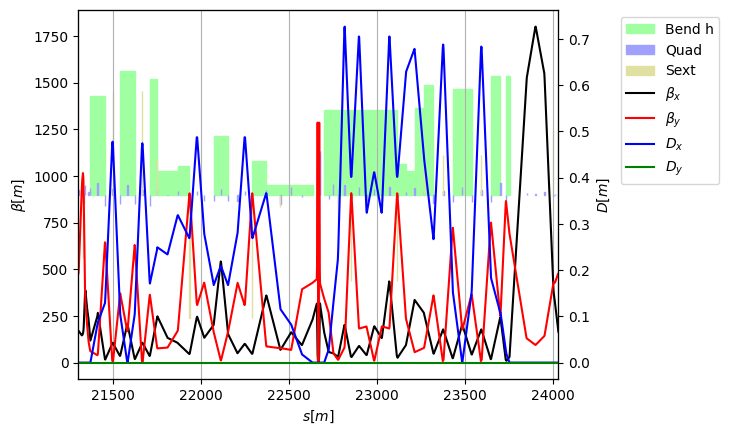

In [25]:
tw.plot()


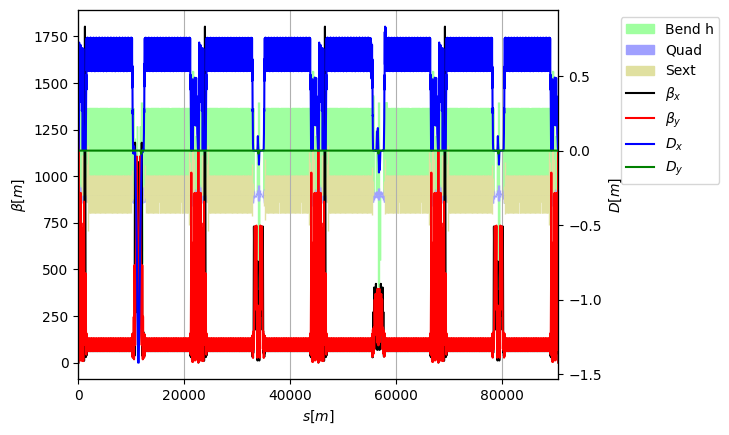

In [26]:
line.twiss().plot()

### Compare natural chromaticities before and after matching

Repeat the calculation with the matched quadrupole strengths and the sextupoles switched off in a new copy. Compare the full-ring natural chromaticities for the nominal and enlarged beta star. Only the new copy has its sextupoles switched off. The original `line` retains the rematched sextupole strengths; `tw0.dqx/dqy` and `tw_ring.dqx/dqy` include their respective sextupole contributions.

Increasing beta star reduces the beta functions in the final-focus quadrupoles and their chromaticity contribution. The total need not scale exactly as $1/\beta^*$: the arcs still contribute, and the matching-section optics and strengths also change.

In [27]:
line_natural = line.copy()
tt_natural = line_natural.get_table()
for name in tt_natural.rows[tt_natural.element_type == 'Sextupole'].name:
    line_natural[name].k2 = 0

tw_natural_matched = line_natural.twiss4d(delta_chrom=1e-6)
print(f'{"Optics":<22} {"Natural Qx prime":>18} {"Natural Qy prime":>18}')
for label, tw_nat in [('Nominal beta star', tw_natural_0),
                      ('10 times beta star', tw_natural_matched)]:
    print(f'{label:<22} {tw_nat.dqx:18.3f} {tw_nat.dqy:18.3f}')
print(f'|Chromaticity| ratio (matched / nominal): '
      f'{abs(tw_natural_matched.dqx / tw_natural_0.dqx):.3f} / '
      f'{abs(tw_natural_matched.dqy / tw_natural_0.dqy):.3f}')

Optics                   Natural Qx prime   Natural Qy prime
Nominal beta star                -512.539          -3145.903
10 times beta star               -227.294           -498.325
|Chromaticity| ratio (matched / nominal): 0.443 / 0.158


### Save the matched ring

Export the ring with the current matched quadrupole strengths and the rematched arc sextupole settings to `fccee_z_matched.json`.

In [28]:
for ip_name in ['ipa', 'ipd', 'ipg', 'ipj']:
    for beta in ['betx', 'bety']:
        np.testing.assert_allclose(
            tw_ring[beta, ip_name] / tw0[beta, ip_name],
            env['beta_factor'], rtol=5e-3,
        )
np.testing.assert_allclose([tw_ring.qx, tw_ring.qy], [tw0.qx, tw0.qy],
                           rtol=0, atol=1e-6)
np.testing.assert_allclose([tw_ring.dqx, tw_ring.dqy], [tw0.dqx, tw0.dqy],
                           rtol=0, atol=1e-3)
line.to_json('fccee_z_matched.json')